# Лабораторная работа: RAG-ассистент по лекции, слайдам и аудио

В этой лабораторной работе мы строим мультимодальную базу знаний по лекции. У нас есть два источника:

* PDF со слайдами `data/4237-4.pdf`;
* аудиозапись лекции `data/4237-4.mp3`.

Обычный RAG по PDF часто теряет визуальный смысл слайдов: схемы, диаграммы, стрелки и расположение элементов. Поэтому мы извлечём из каждого слайда две версии текста:

1. **OCR-текст** — то, что реально написано на слайде.
2. **VLM-описание** — объяснение изображения слайда, включая диаграммы и визуальные связи.

Затем распознаем аудио лекции, создадим Markdown-файлы для индексации и подключим `file_search` из Responses API. В метаданных каждого слайда сохраним имя исходного изображения, чтобы при поиске можно было показать найденный слайд.

> Данная работа используют файлы аудиозаписи и слайдов одного из вебинаров Yandex. Сами материалы отсутствуют в Git-репозитории, но вы можете скачать их, запустив файл `download.bat` в директории `data`. Вы также можете использовать слайда и аудиозапись любой своей лекции.


In [ ]:
%pip install --quiet openai python-dotenv requests pillow pymupdf pandas tqdm yandex-ai-studio-sdk


> **ВНИМАНИЕ**: После установки библиотек рекомендуется перезапустить Kernel ноутбука.

## Авторизация

Используем тот же `.env`, что и в остальных ноутбуках курса.


In [ ]:
!curl -o .env {{url_of_dotenv_file}}


In [ ]:
import base64
import os
from PIL import Image
import io
import re
from pathlib import Path

import fitz
import pandas as pd
import requests
from dotenv import load_dotenv
from IPython.display import Image as IPImage
from IPython.display import Markdown, display
from openai import OpenAI
from tqdm.auto import tqdm
from yandex_ai_studio_sdk import AIStudio

load_dotenv()

folder_id = os.environ["folder_id"]
api_key = os.environ["api_key"]

model = f"gpt://{folder_id}/deepseek-v4.1-flash"
vision_model = f"gpt://{folder_id}/qwen3.6-35b-a3b"

client = OpenAI(
    base_url="https://ai.api.cloud.yandex.net/v1",
    api_key=api_key,
    project=folder_id,
)
sdk = AIStudio(folder_id=folder_id, auth=api_key)

def printx(string):
    display(Markdown(string))

current_dir = Path.cwd()
data_dir = current_dir / "../data"
artifacts_dir = current_dir / "lecture_rag_artifacts"
slides_dir = artifacts_dir / "slides"
texts_dir = artifacts_dir / "texts"
rag_dir = artifacts_dir / "rag_files"
for directory in [slides_dir, texts_dir, rag_dir]:
    directory.mkdir(parents=True, exist_ok=True)

pdf_path = data_dir / "4237-4.pdf"
lecture_audio_path = data_dir / "4237-4.mp3"

print(f"✅ Авторизация настроена (folder_id: {folder_id[:8]}...)")

✅ Авторизация настроена (folder_id: b1gbicod...)


## Часть 1. Конвертируем PDF в изображения

Для начала возьмём слайды лекции, и при помощи библиотеки PyMuPDF преобразуем каждую страницу в PNG. Мы сохраняем изображения как `slide_001.png`, `slide_002.png` и так далее. Эти имена затем попадут в RAG-файлы, чтобы ассистент мог показать найденный слайд.


Рендеринг слайдов:   0%|          | 0/26 [00:00<?, ?it/s]

Сохранено слайдов: 26


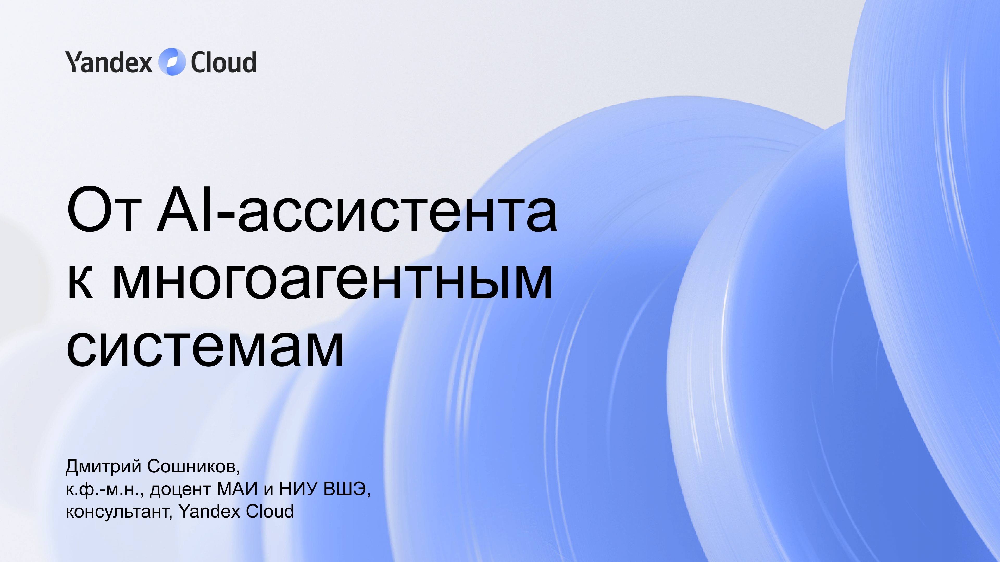

In [3]:
doc = fitz.open(pdf_path)
slide_paths = []
for page_index in tqdm(range(len(doc)), desc="Рендеринг слайдов"):
    page = doc[page_index]
    pix = page.get_pixmap(matrix=fitz.Matrix(2, 2), alpha=False)
    path = slides_dir / f"slide_{page_index + 1:03d}.png"
    pix.save(path)
    slide_paths.append(path)

print(f"Сохранено слайдов: {len(slide_paths)}")
IPImage(filename=str(slide_paths[0]))


## Часть 2. OCR и VLM-описание слайдов

Для каждого слайда будем сохранять два текста:
* исходный текст OCR
* описание, полученное с помощью VLM.

Для начала используем функции OCR и VLM из лекции:

In [ ]:
# Функция для распознавания текста на изображении с помощью сервиса OCR
# (из лекции)
def ocr_recognize(img, language_codes=None, model_name="page"):
    # TODO
    pass

# Функция для генерации осмысленного описания слайда с помощью VLM
# Здесь мы дополнительно передаём функции распознанный текст ocr_text
# и просим сформировать описание слайда по тексту и имеющимся на слайде
# диаграммам. 
def describe_slide(img, ocr_text):
    # TODO
    pass

Теперь прогоним процесс распознавания для всех слайдов.

> Для экономии квоты во время экспериментов можно уменьшить `MAX_SLIDES`, например, до 3. Для полного решения поставьте `MAX_SLIDES = None`.

In [ ]:
MAX_SLIDES = None  # для быстрой проверки можно поставить 3
selected_slides = slide_paths if MAX_SLIDES is None else slide_paths[:MAX_SLIDES]

slide_records = []
for path in tqdm(selected_slides, desc="OCR + VLM"):
    img = Image.open(path)
    # TODO: Добавьте код для OCR и VLM-обработки
    record = {
        "slide_image": path.name,
        "ocr_text": ...,
        "vlm_description": ...,
    }
    slide_records.append(record)
    (texts_dir / f"{path.stem}_ocr.txt").write_text(ocr_text, encoding="utf-8")
    (texts_dir / f"{path.stem}_vlm.md").write_text(vlm_description, encoding="utf-8")

pd.DataFrame(slide_records).head()


OCR + VLM:   0%|          | 0/26 [00:00<?, ?it/s]

,slide_image,ocr_text,vlm_description
0,slide_001.png,Yandex Cloud\nОт Al-ассистента\nк многоагентны...,"\n\nВот описание слайда, подготовленное для RA..."
1,slide_002.png,Построение умных\nассистентов в Yandex Cloud\n...,\n\nВот описание слайда для RAG-системы:\n\n**...
2,slide_003.png,Nvidia CEO Says 2025 Is the Year of AI\nAgents...,\n\nВот описание слайда для RAG-базы знаний:\n...
3,slide_004.png,199x\nОкружение\nКоммуникация\n5\n,"\n\nВот описание слайда, подготовленное для RA..."
4,slide_005.png,Мотивация 1: Эволюционная кибернетика\nПринцип...,\n\nВот описание слайда для RAG-базы знаний:\n...


## Часть 3. Распознаём аудиозапись лекции

Теперь добавим речь преподавателя. Транскрипт лекции часто содержит объяснения, которых нет на слайдах, поэтому он существенно улучшает RAG-ассистента. Для начала добавим функции распознавания речи из лекции.

> Поскольку в примере используется достаточно продолжительная лекция, для успешного завершения будет необходимо установить значение параметра `timeout` при вызове функции `run_deferred` - где-то на 200 секунд.


In [ ]:
# Используйте слегка модифицированную версию функции из лекционного ноутбука
def recognize_long(path: Path,language='ru-RU',speaker_labeling=False,timeout=200):
    # TODO
    pass

lecture_transcript = recognize_long(lecture_audio_path)

In [ ]:
lecture_text = lecture_transcript.channels['0'].final_refinement_text
lecture_text

'Здравствуйте друзья я рад приветствовать вас на очередном вебинаре по ассистентам и многоагентным системам которые так и называется от и я ассистента к многоагентным системам меня зовут дмитрий сошников я доцент высшей школы экономики мои и консультант яндекс клауд и в я начал заниматься многоагентными системами еще в 90 годы когда это было не модным и поэтому с удовольствием сегодня расскажу вам об этой теме этот вебинар является продолжением предыдущего в котором мы рассказывали вам про построение умных ассистентов в облаке яндекс клауд мы рассказывали про то что существует ассистент ай пи ай с помощью которого очень легко строить интеллектуальных ассистентов с которыми можно разговаривать на основе некоторых документов то есть ассистент ай пи ай поддерживает возможность индексации какой то текстовой базы то что называется репливал аугменты дженерейшен поддерживает возможность вызова инструментов и по сути дела является таким самостоятельным интеллектуальным агентом если вам подробн

## Часть 4. Создаём Markdown-файлы для RAG

File Search индексирует текстовые файлы. Поэтому мы создаём один Markdown-файл на слайд и отдельный файл с транскриптом. В начале каждого slide-файла явно указываем `source_image`, чтобы потом иметь возможность найти и показать найденный слайд.


In [ ]:
rag_files = []
for i, record in enumerate(slide_records, start=1):
    slide_md = rag_dir / f"slide_{i:03d}.md"
    # TODO: запишите в файл название слайда, текст OCR и созданное описание VLM
    # можно использвать формат markdown
    rag_files.append(slide_md)
    
# TODO: Также запишите отдельным файлом аудио-транскрипт лекции

print(f"RAG-файлов: {len(rag_files)}")
rag_files[:5]

RAG-файлов: 27


[WindowsPath('d:/GIT/ai-studio-course/8-other-services/Labs/lecture_rag_artifacts/rag_files/slide_001.md'),
 WindowsPath('d:/GIT/ai-studio-course/8-other-services/Labs/lecture_rag_artifacts/rag_files/slide_002.md'),
 WindowsPath('d:/GIT/ai-studio-course/8-other-services/Labs/lecture_rag_artifacts/rag_files/slide_003.md'),
 WindowsPath('d:/GIT/ai-studio-course/8-other-services/Labs/lecture_rag_artifacts/rag_files/slide_004.md'),
 WindowsPath('d:/GIT/ai-studio-course/8-other-services/Labs/lecture_rag_artifacts/rag_files/slide_005.md')]

## Часть 5. Создаём Vector Store и загружаем файлы

Теперь используем знакомый нам по предыдущему разделу курса паттерн файлового поиска: загружаем файлы через `client.files.create`, создаём Vector Store и добавляем файлы в индекс.


In [ ]:
# TODO: Используйте код для создания файлового индекса из лекции по файловому поиску

file_search_tool = {
    "type": "file_search",
    "vector_store_ids": [vector_store.id],
    "max_num_results": 5,
}

## Часть 6. Ассистент по лекции

Создадим диалогового ассистента, который сможет отвечать на вопрос по лекции, используя файловый поиск. После ответа мы также извлекаем имена найденных файлов, и показываем конкретные слайды, если они фигурировали в результатах поиска.


Основные идеи **ReAct-агента** (от англ. *Reason + Act* — «Рассуждай и Действуй») сводятся к тому, что агент **чередует процесс мышления (рассуждений) и действий**, чтобы эффективно решать сложные задачи с использованием внешних инструментов.

### Основные идеи ReAct-агента:

1. **Цикл «Думай — Действуй — Наблюдай» (Think → Act → Observe)**  
   Агент не пытается дать ответ сразу. Вместо этого он:
   - **Think (Думай)** — анализирует текущую ситуацию и планирует, что делать дальше.
   - **Act (Действуй)** — выполняет действие, например, запрашивает данные из внешнего источника (например, меню ресторана).
   - **Observe (Наблюдай)** — получает результат действия и анализирует его.
   - Затем цикл повторяется, пока задача не будет решена.

2. **Использование внешних инструментов (Tools)**  
   Агент может обращаться к разным инструментам:
   - Получать информацию (например, меню по протоколу MCP).
   - Использовать сложные функции, например, «сомелье» для подбора вина на основе вкусовых предпочтений.

3. **Интеллектуальное управление потоком**  
   Агент выступает как «умный посредник» между пользователем и ресурсами, принимая решения, какие действия выполнять и в каком порядке.

4. **Итеративность и адаптивность**  
   Агент может корректировать свои действия на основе полученных результатов, что делает его гибким и способным к решению сложных, многоэтапных задач.

---

### Релевантные слайды:

- **Слайд 21**: Показывает архитектуру ReAct-агента, его взаимодействие с пользователем и инструментами, а также пример использования (ресторан, меню, сомелье).  
  ➤ Центральный цикл: *Think, Act, Observe*.

- **Слайд 22**: Детально иллюстрирует цикл работы агента — от запроса (Query) до завершения (END), включая обратную связь через *Observation*.  
  ➤ Четко виден итеративный процесс.

---

💡 **Итог**: ReAct — это не просто модель, а **стратегия поведения агента**, которая позволяет ему "думать как человек": сначала размышлять, потом действовать, смотреть, что получилось, и снова думать. Это делает его мощным инструментом для решения сложных задач в реальных приложениях.

Найденные файлы: {'slide_021.md', 'slide_008.md', 'slide_020.md', 'lecture_transcript.md', 'slide_022.md'}


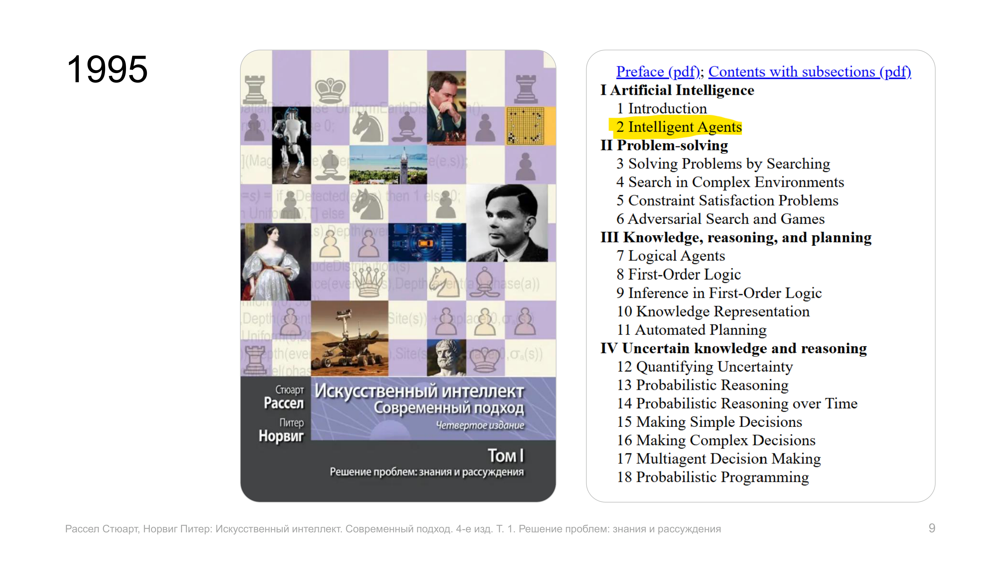

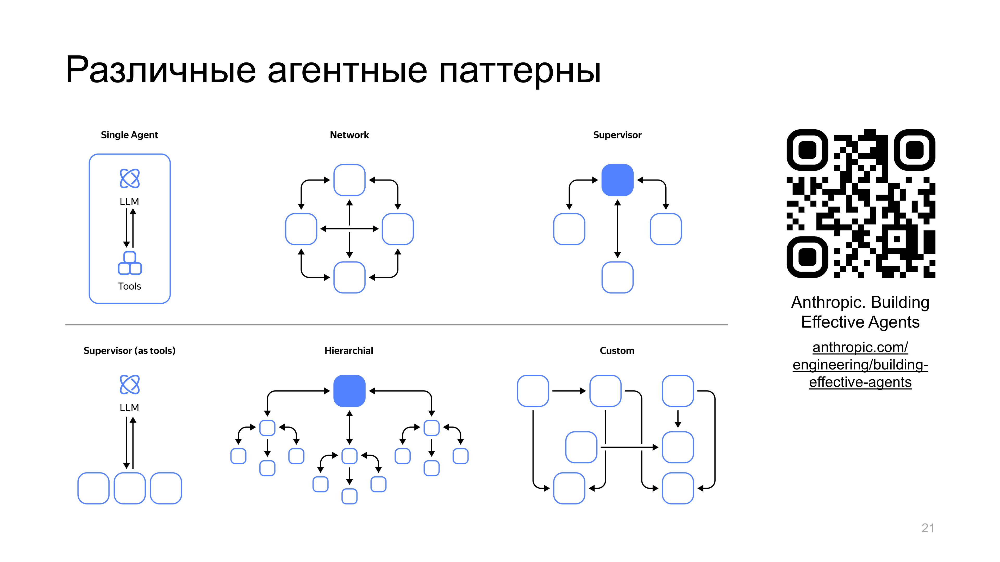

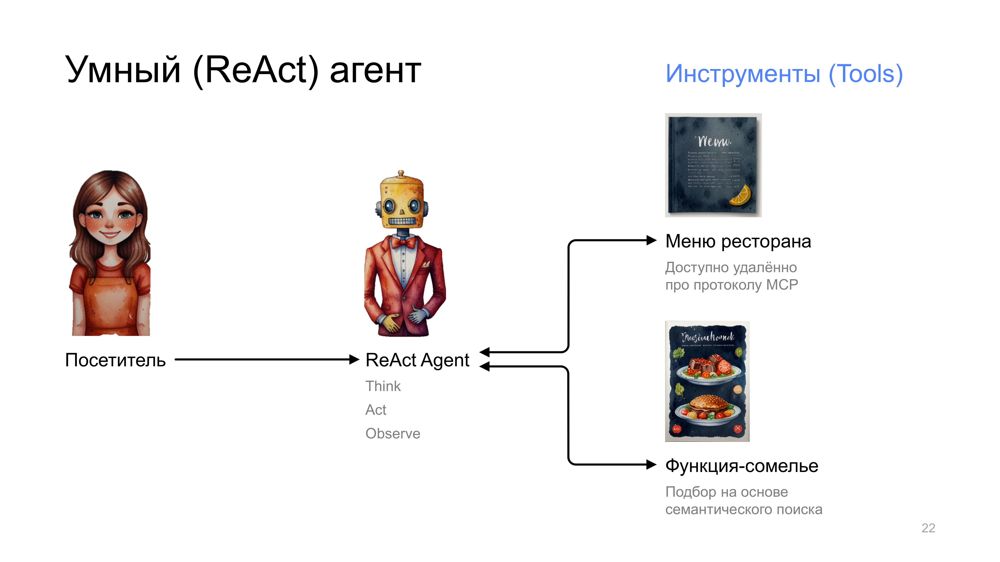

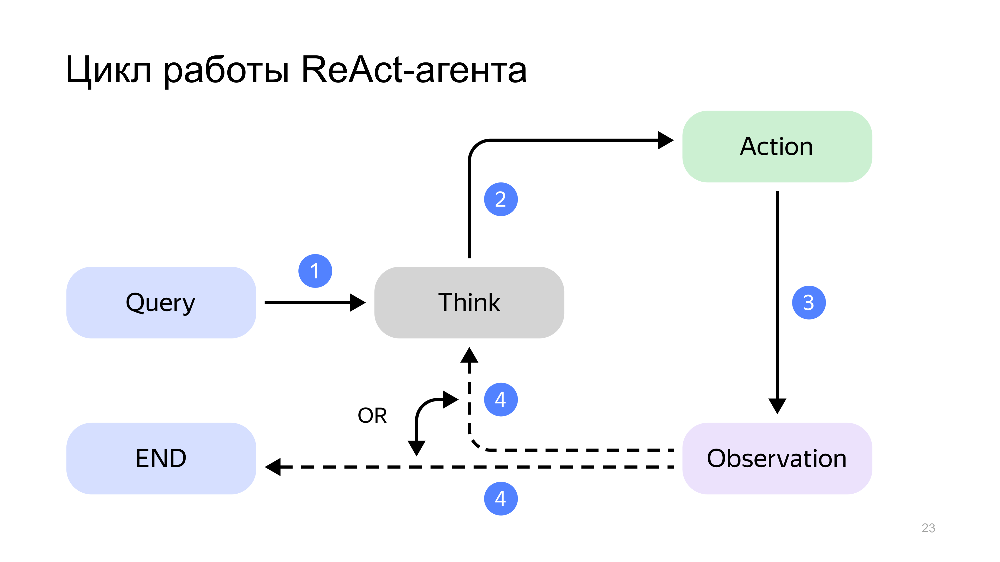

In [ ]:
assistant_instruction = """Ты — учебный ассистент по лекции.
Всегда используй file_search, отвечай на русском языке, объясняй простым языком.
Если в найденных источниках есть слайды, ссылайся на номера слайдов.
"""

def ask_lecture(question: str):
    # TODO: Сделайте Responses-запрос с инструментом файлового поиска
    pass

def show_found_slides(result):
    # TODO: Пройдитесь по ответу модели, найдите все найденные файловым поиском
    # фрагменты, и отобразите соответствующие слайды (в виде картинок)

answer = ask_lecture("Объясни основные идеи ReAct-агента и покажи релевантные слайды.")
show_found_slides(answer)


## Очистка ресурсов

Если вы экспериментируете в учебном каталоге, после занятия можно удалить созданный Vector Store и загруженные файлы. Не запускайте эту ячейку, если хотите продолжить общаться с ассистентом.


In [26]:
client.vector_stores.delete(vector_store_id=vector_store.id)
for uploaded in uploaded_files:
     client.files.delete(file_id=uploaded.id)


## Что получилось

Мы собрали RAG-ассистента, который использует сразу несколько источников:

* OCR-текст слайдов;
* VLM-описание визуального содержания;
* транскрипт аудиозаписи лекции;
* связь найденных текстовых фрагментов с исходными изображениями слайдов.

Такой подход полезен для образовательных материалов: студент может задавать вопросы по лекции, а ассистент не только отвечает текстом, но и помогает найти нужный слайд.
